# ***CT5146: Introduction to NLP***

# ***Assignment 3: Knowledge Extraction*** (Total 100 marks)

This assignment focuses on **Named Entity Recognition (NER)**, a knowledge extraction task that identifies entity mentions (text spans) and assigns entity types such as **PER** (person), **ORG** (organisation), and **LOC** (location). You will examine entity annotations, apply an NER system, assess its predictions against a gold standard, and investigate its errors.

**Dataset Requirement:** Your chosen dataset must contain named entity annotations, such as entity spans and corresponding entity types (e.g., PER, ORG, LOC), to support NER extraction and evaluation.

---
## **Task Roadmap**

| # | Section | Focus | Marks |
|---|---|---|---:|
| 1 | **Dataset & NER Task Understanding** | Choose an NER dataset; inspect labels, BIO tagging and entity distributions | **30** |
| 2 | **NER Extraction & Evaluation** | Run a pretrained NER system and evaluate against annotated data | **40** |
| 3 | **Error Analysis & Improvement** | Investigate errors, improve the system, and compare results | **30** |
| | | **Total** | **100** |

**Workflow:** NER dataset → annotation analysis → baseline predictions → entity-level evaluation → targeted improvement → comparison.

The lab's Hugging Face NER pipeline is a useful starting point, but this assignment requires evaluation against **gold entity annotations**.

## **Dataset: What You Need**

Choose **one publicly available dataset with named-entity annotations**. For a social-media focus, **WNUT 2017 Emerging and Rare Entity Recognition** is an appropriate example. Other possible choices include **CoNLL-2003** or a suitable language-specific **WikiANN** subset. You may choose another valid NER dataset.

- WNUT 2017: https://huggingface.co/datasets/leondz/wnut_17
- CoNLL-2003: https://huggingface.co/datasets/eriktks/conll2003
- WikiANN: https://huggingface.co/datasets/unimelb-nlp/wikiann

**Requirements:** The dataset must provide token-level entity annotations (e.g. BIO labels) or gold entity spans/types. It should have a usable evaluation split, or you must make and document a reproducible train/validation/test split. Keep the **test set for final reporting**, not for selecting changes. If an existing dataset or model uses a different tag set, explain how you handle the mismatch; do not silently count unmatched categories as equivalent.

You may use a small, clearly described evaluation subset if computing resources are limited. Apply the **same held-out examples** for baseline and improved methods.


<h3>Useful References</h3>

<div style="display:flex; flex-wrap:wrap; gap:12px; margin:15px 0;">

  <a href="https://huggingface.co/docs/datasets/load" target="_blank"
     style="background-color:#2563eb; color:white; padding:10px 16px;
            border-radius:8px; text-decoration:none; font-weight:bold;">
    Hugging Face Datasets ↗
  </a>

  <a href="https://huggingface.co/docs/transformers/tasks/token_classification"
     target="_blank"
     style="background-color:#2563eb; color:white; padding:10px 16px;
            border-radius:8px; text-decoration:none; font-weight:bold;">
    Transformers Token Classification ↗
  </a>

  <a href="https://github.com/chakki-works/seqeval" target="_blank"
     style="background-color:#2563eb; color:white; padding:10px 16px;
            border-radius:8px; text-decoration:none; font-weight:bold;">
    seqeval Evaluation ↗
  </a>

</div>


# Installing and Importing Packages

> **Note:** Setup is not directly graded. You may use packages such as `datasets`, `transformers`, `torch`, `pandas`, `matplotlib`, `spacy`, and `seqeval`. Install only what your approach needs.

In [ ]:
# YOUR CODE HERE
import pandas as pd
from datasets import load_dataset_builder, load_dataset
import matplotlib.pyplot as plt
from transformers import pipeline, AutoTokenizer, AutoModelForTokenClassification
import torch
import string
import re
from tabulate import tabulate
from google.colab import files
import os

---
# **Section 1: Dataset & NER Task Understanding**
### `Total = 30 marks`

| Task | What you will do | Marks |
|---|---|---:|
| **1a** | Select, load, and describe an annotated NER dataset | **10** |
| **1b** | Analyse entity categories and BIO annotations | **10** |
| **1c** | Visualise the dataset and explain observations | **10** |

## **1a: Dataset Selection and Loading** (10 marks)

Select and load an NER dataset. Show the dataset splits (or explain your own reproducible split), the number of sentences/documents, and at least **three annotated examples** with tokens and their entity tags.

**Requirement:** Identify the dataset source, language, entity types, and annotation format. Explain why the dataset is suitable for NER, ensuring that it provides token-level entity annotations or gold entity spans and types.

In [ ]:
# YOUR CODE HERE

# The dataset source is https://huggingface.co/datasets/unimelb-nlp/wikiann
# Set the language to English to get only the English dataset.
ds_builder = load_dataset_builder("unimelb-nlp/wikiann", 'en')
ds_builder.info.features

{'tokens': List(Value('string')),
 'ner_tags': List(ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'])),
 'langs': List(Value('string')),
 'spans': List(Value('string'))}

In [ ]:
ner_tags_list = ds_builder.info.features['ner_tags'].feature.names
print(f"Entity types could be found on ner_tags which are: {ner_tags_list}")
print("There are 7 NER tags which consists of 3 types; Person, Organisation and Location. O stands for Outside of named entity.")

Entity types could be found on ner_tags which are: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
There are 7 NER tags which consists of 3 types; Person, Organisation and Location. O stands for Outside of named entity.


In [ ]:
dataset = load_dataset("unimelb-nlp/wikiann", 'en') # Load the English dataset

In [ ]:
dataset

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 20000
    })
})

In [ ]:
train_ds = dataset['train']
val_ds = dataset['validation']
test_ds = dataset['test']

In [ ]:
# Convert each dataset into pandas
train_df = train_ds.to_pandas()
val_df = val_ds.to_pandas()
test_df = test_ds.to_pandas()

In [ ]:
pd.set_option('display.max_colwidth', None) # Remove text truncation for better preview the text

In [ ]:
print(f"Train df shape: {train_df.shape}")

Train df shape: (20000, 4)


The 3 dataframes; test, validation and test set each has 20000, 10000 and 10000 number of sentences.

In [ ]:
train_df.head()

,tokens,ner_tags,langs,spans
0,"[R.H., Saunders, (, St., Lawrence, River, ), (, 968, MW, )]","[3, 4, 0, 3, 4, 4, 0, 0, 0, 0, 0]","[en, en, en, en, en, en, en, en, en, en, en]","[ORG: R.H. Saunders, ORG: St. Lawrence River]"
1,"[;, ', '', Anders, Lindström, '', ']","[0, 0, 0, 1, 2, 0, 0]","[en, en, en, en, en, en, en]",[PER: Anders Lindström]
2,"[Karl, Ove, Knausgård, (, born, 1968, )]","[1, 2, 2, 0, 0, 0, 0]","[en, en, en, en, en, en, en]",[PER: Karl Ove Knausgård]
3,"[Atlantic, City, ,, New, Jersey]","[5, 6, 6, 6, 6]","[en, en, en, en, en]","[LOC: Atlantic City , New Jersey]"
4,"[Her, daughter, from, the, second, marriage, was, Marie, d'Agoult, (, 1805–1876, ), ,, who, in, turn, gave, birth, to, several, children, ,, among, them—from, her, liaison, to, Franz, Liszt, –-, Cosima, Wagner, (, 1837–1930, ), .]","[0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 1, 2, 0, 0, 0, 0]","[en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en, en]","[PER: Marie d'Agoult, PER: Franz Liszt, PER: Cosima Wagner]"


In [ ]:
# Drop langs column which is unnecessary
train_df.drop('langs', axis=1, inplace=True)
val_df.drop('langs', axis=1, inplace=True)
test_df.drop('langs', axis=1, inplace=True)

We can see the ner_tags are showing in their index number, not the actual texts that belong on the entities. Annotation format is in indices of the entity list.

In [ ]:
# Three annotated examples with tokens and their entity tags
def get_token_entity(df, n):
    """
    Function for getting the tokens from certain dataframe and the
    desired number of examples.
    ner_tags_list = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
    """
    for i in range(n): # Get n number of rows from df
        ner_tags_texts = [] # List to save the NER entities in text
        tokens = list(df.loc[i]['tokens']) # Get the token in list
        for j in df.loc[i]['ner_tags']: # Since the column ner_tags are in indices, we use those directly on the ner_tags_list to get the entity texts
            ner_tag = ner_tags_list[j]
            ner_tags_texts.append(ner_tag)
        print(f"Tokens: {tokens},\nNER tags: {ner_tags_texts}\n")

get_token_entity(train_df, 3) # Get 3 top examples with tokens and their entity tags.

Tokens: ['R.H.', 'Saunders', '(', 'St.', 'Lawrence', 'River', ')', '(', '968', 'MW', ')'],
NER tags: ['B-ORG', 'I-ORG', 'O', 'B-ORG', 'I-ORG', 'I-ORG', 'O', 'O', 'O', 'O', 'O']

Tokens: [';', "'", "''", 'Anders', 'Lindström', "''", "'"],
NER tags: ['O', 'O', 'O', 'B-PER', 'I-PER', 'O', 'O']

Tokens: ['Karl', 'Ove', 'Knausgård', '(', 'born', '1968', ')'],
NER tags: ['B-PER', 'I-PER', 'I-PER', 'O', 'O', 'O', 'O']



In [ ]:
# Explain why the dataset is suitable for NER, ensuring that it provides token-level entity annotations or gold entity spans and types.
print("The dataset has NER tags already set in the indices of the NER tags list.")
print("Column 'ner_tags' is the token level entity annotation.")
print("Also the dataset has the gold span provided with the types (e.g. PER: Karl Ove Knausgård)")

The dataset has NER tags already set in the indices of the NER tags list.
Column 'ner_tags' is the token level entity annotation.
Also the dataset has the gold span provided with the types (e.g. PER: Karl Ove Knausgård)


## **1b: Entity Labels and BIO Annotation** (10 marks)

Inspect the available entity types and BIO tags. Compute a table showing the **number of gold entity mentions per entity type** in the split you are analysing (not merely the number of tokens labelled B-/I-). Display at least **two examples** of multi-token or otherwise interesting entities, and explain the role of **B**, **I**, and **O** in those examples.

If the dataset does not use BIO tags, show how its span annotations correspond to BIO labels. Avoid inventing labels for unannotated text.

In [ ]:
# YOUR CODE HERE
# Compute a table showing the number of gold entity mentions per entity type
from collections import Counter

def count_span_entity(df):
    entity_counts = Counter() # Counter dict for entity counts
    for row in df['spans']:
        for span in row:
            entity_type = span.split(":", 1)[0] # Split by colon and get only the first occurance
            entity_counts[entity_type] += 1 # Add 1 on the corresponding entity type
    return entity_counts

train_entity_counts = count_span_entity(train_df)
val_entity_counts = count_span_entity(val_df)
test_entity_counts = count_span_entity(test_df)

table = pd.DataFrame({
    "train": train_entity_counts,
    "val": val_entity_counts,
    "test": test_entity_counts,
})
table.loc['Total'] = table.sum()
table_title = "<Number of Gold Entity Counts per Entity Type on All Datasets>"
print(table_title)
display(table)


<Number of Gold Entity Counts per Entity Type on All Datasets>


,train,val,test
ORG,9422,4677,4745
PER,9164,4635,4556
LOC,9345,4834,4657
Total,27931,14146,13958


In [ ]:
list(train_entity_counts)

['ORG', 'PER', 'LOC']

In [ ]:
list(train_entity_counts.items())

[('ORG', 9422), ('PER', 9164), ('LOC', 9345)]

In [ ]:
# Display at least two examples of multi-token or otherwise interesting entities, and explain the role of B, I, and O in those examples.

def get_entity_text(df, n):
    """Function to convert ner_tags into texts"""
    data = df.loc[n] # Data to convert the ner_tags
    ner_tags_text = [ner_tags_list[n] for n in data['ner_tags']] # Match the index rom ner_tags_list
    return ner_tags_text

# Spans and NER tags for row 1526
data_1526_spans = train_df.loc[1526]['spans']
data_1526 = get_entity_text(train_df, 1526)
print("- Data loc 1526 spans and entity:")
print(data_1526_spans)
print(data_1526)

# Spans and NER tags for row 19990
data_19990_spans = train_df.loc[19990]['spans']
data_19990 = get_entity_text(train_df, 19990)
print("\n- Data loc 19990 spans and entity:")
print(data_19990_spans)
print(data_19990)

print("\n- Role of B, I and O:")
print("B is for beginning of the span that belongs onto a certain NER tag.")
print("'Big' has B-PER since it is the start of a person 'Big Tiny Little.'")
print("I is for inside of a certain tag followed by B or previous I.")
print("For example 'Tiny' and 'Little' has the tag I-PER since it's an inside token for a person.")
print("O is for outside that does not belong to any of the tags.")

- Data loc 1526 spans and entity:
['PER: Big Tiny Little' 'PER: Bessie Smith' 'PER: Dick Hyman'
 'ORG: Carnegie Hall']
['O', 'O', 'O', 'O', 'O', 'O', 'B-PER', 'I-PER', 'I-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PER', 'I-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PER', 'I-PER', 'O', 'O', 'O', 'O', 'O', 'B-ORG', 'I-ORG', 'O']

- Data loc 19990 spans and entity:
['ORG: Beltzville State Park' 'LOC: Carbon County']
['B-ORG', 'I-ORG', 'I-ORG', 'O', 'B-LOC', 'I-LOC', 'O']

- Role of B, I and O:
B is for beginning of the span that belongs onto a certain NER tag.
'Big' has B-PER since it is the start of a person 'Big Tiny Little.'
I is for inside of a certain tag followed by B or previous I.
For example 'Tiny' and 'Little' has the tag I-PER since it's an inside token for a person.
O is for outside that does not belong to any of the tags.


## **1c: Visualisation and Explanation** (10 marks)

Create **two labelled visualisations**, such as (i) entity-mention counts by type and (ii) sentence lengths or number of entities per sentence.

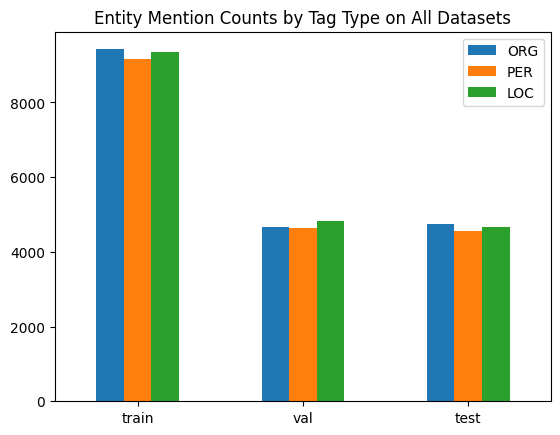

In [ ]:
# YOUR CODE HERE
# Plot entity mention counts by type
table_tp = table.drop("Total")
table_tp.T.plot(kind="bar")
plt.title("Entity Mention Counts by Tag Type on All Datasets")
plt.xticks(rotation=0)
plt.show()

In [ ]:
train_df.head()

,tokens,ner_tags,spans
0,"[R.H., Saunders, (, St., Lawrence, River, ), (, 968, MW, )]","[3, 4, 0, 3, 4, 4, 0, 0, 0, 0, 0]","[ORG: R.H. Saunders, ORG: St. Lawrence River]"
1,"[;, ', '', Anders, Lindström, '', ']","[0, 0, 0, 1, 2, 0, 0]",[PER: Anders Lindström]
2,"[Karl, Ove, Knausgård, (, born, 1968, )]","[1, 2, 2, 0, 0, 0, 0]",[PER: Karl Ove Knausgård]
3,"[Atlantic, City, ,, New, Jersey]","[5, 6, 6, 6, 6]","[LOC: Atlantic City , New Jersey]"
4,"[Her, daughter, from, the, second, marriage, was, Marie, d'Agoult, (, 1805–1876, ), ,, who, in, turn, gave, birth, to, several, children, ,, among, them—from, her, liaison, to, Franz, Liszt, –-, Cosima, Wagner, (, 1837–1930, ), .]","[0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 1, 2, 0, 0, 0, 0]","[PER: Marie d'Agoult, PER: Franz Liszt, PER: Cosima Wagner]"


In [ ]:
# Count sentence, span and tag lengths
train_df['tokens_len'] = train_df['ner_tags'].apply(len)
train_df['entity_len'] = train_df['spans'].apply(len)
train_df['bi_tag_len'] = train_df['ner_tags'].apply(
    lambda tags: sum(tag != 0 for tag in tags)
)

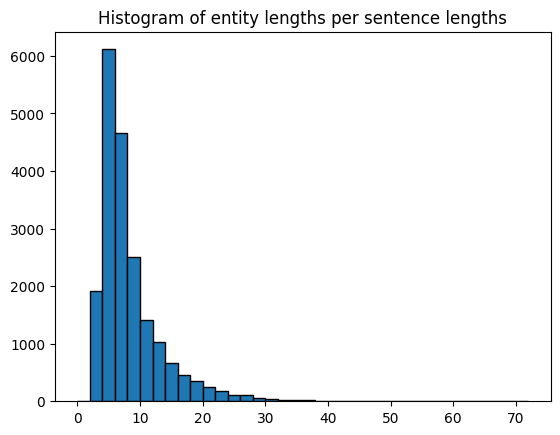

In [ ]:
# Plot a histogram of the entity lengths per sentence lengths.
plt.hist(
    x=train_df['tokens_len'],
    bins=range(0, int(train_df['entity_len'].max() / 2), 2),
    edgecolor='black')
plt.title("Histogram of entity lengths per sentence lengths")
plt.show()

**Briefly explain:**

- why you chose the dataset;
- what the label distribution reveals;
- one potential annotation or ambiguity challenge for NER.

**Written explanation:** Maximum **100 words** (figures, captions, and code excluded).

**Your explanation (≤100 words):**

`# YOUR ANSWER HERE`
- Choose the dataset because it had BIO tags and gold entity spans.
- Label distributions show each three tags are equally distributed on all datasets.
- Ambiguity in identifying words that could belong on both tags such as 'Irish'. Irish could be a LOC or ORG depending on the context. (e.g. row 146), or '25' being considered as ORG on row 117 while mostly it's a plain number. Distinguishing the token by the context would be a challenge.

---
# **Section 2: NER Extraction & Evaluation**
### `Total = 40 marks`

Use an existing **pretrained NER system** (for example, a Hugging Face token-classification pipeline such as `dslim/bert-base-NER`, or a suitable spaCy NER model). **Training or fine-tuning from scratch is not required.** Ensure the model's entity label set is compatible with the dataset, or explicitly restrict evaluation to a justified common label set.

| Task | What you will do | Marks |
|---|---|---:|
| **2a** | Build a reproducible baseline NER extraction pipeline | **15** |
| **2b** | Evaluate predictions with entity-level precision, recall and F1 | **15** |
| **2c** | Explain the baseline and its results | **10** |

## **2a: Implement Baseline Named Entity Recognition** (15 marks)

Load an appropriate pretrained NER model and use it to identify entities in your chosen evaluation data.

Your code should:
1. show which model you used and its supported entity categories;
2. convert model output to **entity spans and labels** for comparison with the gold annotations;
3. display a table containing **at least five sentences**, their gold entity mentions, and predicted entity mentions.

**Be careful with tokenisation:** Subword tokens, character offsets, multi-word entities, and label mappings may differ between your dataset and model. Document the alignment strategy. Avoid evaluating raw tokens against spans as if they were identical.

In [ ]:
# YOUR CODE HERE
# Initializing the pipeline for Named Entity Recognition
# Choose https://huggingface.co/dslim/bert-base-NER NER model
ner_extractor = pipeline(model="dslim/bert-base-NER", aggregation_strategy="none")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
# Create a full sentence column by joining the tokens together

def token_reconstruct(tokens):
    """
    Create a full sentence by joining the tokens.
    Make sure to manually work on the punctuations since we don't always need
    space before and after the certain punctuations otherwise the token will be
    broken.
    """
    sentence = ""
    punctuation = set(string.punctuation) - {"(", ")", "[", "]", "{", "}", "<", ">"} # Manually set punctuation
    no_space_after = {"(", "{", "[", "<"}
    no_space_before = {")", "}", "]", ">", "'"}

    for token in tokens:
        if not sentence:
            sentence = token
        elif token in no_space_before:
            sentence += token
        elif sentence[-1] in no_space_after: # check the last added token's last index letter. No need to have space before adding the token
            sentence += token
        elif token in punctuation:
            sentence += token
        else:
            sentence += " " + token
    return sentence

def create_full_sentence(df):
    df['sentences'] = df['tokens'].apply(token_reconstruct)



In [ ]:
create_full_sentence(train_df)

In [ ]:
train_df.head(10)

,tokens,ner_tags,spans,sentences
0,"[R.H., Saunders, (, St., Lawrence, River, ), (, 968, MW, )]","[3, 4, 0, 3, 4, 4, 0, 0, 0, 0, 0]","[ORG: R.H. Saunders, ORG: St. Lawrence River]",R.H. Saunders (St. Lawrence River) (968 MW)
1,"[;, ', '', Anders, Lindström, '', ']","[0, 0, 0, 1, 2, 0, 0]",[PER: Anders Lindström],;' '' Anders Lindström '''
2,"[Karl, Ove, Knausgård, (, born, 1968, )]","[1, 2, 2, 0, 0, 0, 0]",[PER: Karl Ove Knausgård],Karl Ove Knausgård (born 1968)
3,"[Atlantic, City, ,, New, Jersey]","[5, 6, 6, 6, 6]","[LOC: Atlantic City , New Jersey]","Atlantic City, New Jersey"
4,"[Her, daughter, from, the, second, marriage, was, Marie, d'Agoult, (, 1805–1876, ), ,, who, in, turn, gave, birth, to, several, children, ,, among, them—from, her, liaison, to, Franz, Liszt, –-, Cosima, Wagner, (, 1837–1930, ), .]","[0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 1, 2, 0, 0, 0, 0]","[PER: Marie d'Agoult, PER: Franz Liszt, PER: Cosima Wagner]","Her daughter from the second marriage was Marie d'Agoult (1805–1876), who in turn gave birth to several children, among them—from her liaison to Franz Liszt –- Cosima Wagner (1837–1930)."
5,"[St., Mary, 's, Catholic, Church, (, Sandusky, ,, Ohio, )]","[3, 4, 4, 4, 4, 4, 4, 4, 4, 4]","[ORG: St. Mary 's Catholic Church ( Sandusky , Ohio )]","St. Mary 's Catholic Church (Sandusky, Ohio)"
6,"[Shhh, ..., Do, n't, Tell, '']","[3, 4, 4, 4, 4, 0]",[ORG: Shhh ... Do n't Tell],Shhh ... Do n't Tell ''
7,"[Antonín, Rýgr, (, 1970–72, )]","[1, 2, 0, 0, 0]",[PER: Antonín Rýgr],Antonín Rýgr (1970–72)
8,"[*Inducted, into, the, United, States, Hockey, Hall, of, Fame, in, 2015]","[0, 0, 0, 3, 4, 4, 4, 4, 4, 0, 0]",[ORG: United States Hockey Hall of Fame],*Inducted into the United States Hockey Hall of Fame in 2015
9,"[Dia, Evtimova, Catalina, Castaño, Dinah, Pfizenmaier, Tatjana, Malek]","[1, 2, 1, 2, 1, 2, 1, 2]","[PER: Dia Evtimova, PER: Catalina Castaño, PER: Dinah Pfizenmaier, PER: Tatjana Malek]",Dia Evtimova Catalina Castaño Dinah Pfizenmaier Tatjana Malek


In [ ]:
# Preview the first 10 row samples to see how ner_extrator works
sample_10 = train_df[:10]
sample_10['tokens']

entities = ner_extractor(s for s in sample_10['sentences'])

for entity_groups in entities:
    print(entity_groups)


[{'entity': 'B-PER', 'score': np.float32(0.99833554), 'index': 1, 'word': 'R', 'start': 0, 'end': 1}, {'entity': 'B-PER', 'score': np.float32(0.9416722), 'index': 2, 'word': '.', 'start': 1, 'end': 2}, {'entity': 'I-PER', 'score': np.float32(0.95128566), 'index': 3, 'word': 'H', 'start': 2, 'end': 3}, {'entity': 'I-PER', 'score': np.float32(0.8072024), 'index': 4, 'word': '.', 'start': 3, 'end': 4}, {'entity': 'I-PER', 'score': np.float32(0.9987594), 'index': 5, 'word': 'Saunders', 'start': 5, 'end': 13}, {'entity': 'B-LOC', 'score': np.float32(0.995291), 'index': 7, 'word': 'St', 'start': 15, 'end': 17}, {'entity': 'I-LOC', 'score': np.float32(0.9979983), 'index': 8, 'word': '.', 'start': 17, 'end': 18}, {'entity': 'I-LOC', 'score': np.float32(0.9949699), 'index': 9, 'word': 'Lawrence', 'start': 19, 'end': 27}, {'entity': 'I-LOC', 'score': np.float32(0.9975479), 'index': 10, 'word': 'River', 'start': 28, 'end': 33}]
[{'entity': 'B-PER', 'score': np.float32(0.99975866), 'index': 5, 'wo

In [ ]:
# Convert model output to entity spans and labels for comparison with the gold annotations
def ner_extract(df):
    """
    Function to extract NER tag and span for the df that is passed in
    """
    entities = ner_extractor(s for s in df['sentences'])

    labelled_spans = [] # List we will append on the df. Format: (TAG: token)

    for entity_groups in entities:
        sentence_entities = []
        full_token = ""

        for entity in entity_groups:
            curr_token = entity['word']
            tag = entity['entity_group']

            if curr_token.startswith("##"): # If the token is I type
                full_token += curr_token[2:] # Do not include ##
            else:
                if full_token:
                    # Remove spaces before punctuation
                    full_token = re.sub(r"\s+([.,!?;:'’])", r"\1", full_token)
                    # Remove spaces after apostrophes
                    full_token = re.sub(r"(['’])\s+", r"\1", full_token)

                    sentence_entities.append(f"{pre_tag}: {full_token}")

                full_token = curr_token
                pre_tag = tag

        if full_token: # Combine the full tokens together and append
            # Remove spaces before punctuation
            full_token = re.sub(r"\s+([.,!?;:'’])", r"\1", full_token)
            # Remove spaces after apostrophes
            full_token = re.sub(r"(['’])\s+", r"\1", full_token)

            sentence_entities.append(f"{pre_tag}: {full_token}")

        labelled_spans.append(sentence_entities)

    df['predicted_spans'] = labelled_spans

    return df.head(10)



In [ ]:
# Apply train_df on ner_extract
ner_extract(train_df)

In [ ]:
# Display a table containing at least five sentences, their gold entity mentions, and predicted entity mentions.
train_df[['sentences', 'spans', 'predicted_spans']].head()

,sentences,spans,predicted_spans
0,R.H. Saunders (St. Lawrence River) (968 MW),"[ORG: R.H. Saunders, ORG: St. Lawrence River]","[PER: R, PER: . H. Saunders, LOC: St. Lawrence River]"
1,;' '' Anders Lindström ''',[PER: Anders Lindström],[PER: Anders Lindström]
2,Karl Ove Knausgård (born 1968),[PER: Karl Ove Knausgård],[PER: Karl Ove Knausgård]
3,"Atlantic City, New Jersey","[LOC: Atlantic City , New Jersey]","[LOC: Atlantic City, LOC: New Jersey]"
4,"Her daughter from the second marriage was Marie d'Agoult (1805–1876), who in turn gave birth to several children, among them—from her liaison to Franz Liszt –- Cosima Wagner (1837–1930).","[PER: Marie d'Agoult, PER: Franz Liszt, PER: Cosima Wagner]","[PER: Marie d'Agoult, PER: Franz Liszt, PER: Cosima Wagner]"


#### **(For my use) Save and loading back the file to pkl**

In [ ]:
train_df.to_pickle("train_df_ner.pkl") # Save the worked train_df as pkl

In [ ]:
# Download the saved pkl file locally
files.download("train_df_ner.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
os.listdir()

['.config', 'train_df_ner.pkl', 'sample_data']

In [ ]:
uploaded = files.upload()

Saving train_df_ner.pkl to train_df_ner.pkl


In [ ]:
train_df_ner = pd.read_pickle('/content/train_df_ner.pkl')

## **2b: Evaluation of NER Performance** (15 marks)

Evaluate the baseline on a **held-out, gold-annotated** evaluation set. Report:

- **Entity-level precision, recall, and F1-score** using **exact span + entity-type matching**;
- a **per-entity-type** result table for the types you evaluate;
- the total number of evaluated sentences and gold entities.

You may use `seqeval` when the reference and predicted BIO sequences are correctly aligned, or implement an equivalent exact-span evaluator. If restricting to common entity types or a subset, clearly state the restrictions and keep them consistent in Section 3.

> **Note:** Do not use the pretrained model's confidence scores as a substitute for gold-standard evaluation. A few manually inspected examples alone are not sufficient for this task.

In [ ]:
sample_10 = train_df_ner.head(10)

In [ ]:
# Create a function counting the TP, FP, FN predictions compared to the gold span + entity type

def evaluate_confusion_matrix_and_count(df, gold_col, pred_col):
    """
    - Calculate the confution matrix by comparing the entity type and span on
    both gold and pred.
    - Make gold and pred texts to be as a set and compare how many is found on
    each gold set and pred set to calculate the tp, fp and fn.
    - Create new column to count tp, fp and fn for each row. -> Needed for Section 3
    - With the counted tp, fp and fn, we can easily calculate the precision,
    recall and f1 score.
    """

    # Total counts be added here
    tp = 0
    fp = 0
    fn = 0

    # Counts of each row as a list to create new column on the df
    tp_list = []
    fp_list = []
    fn_list = []


    golds = df[gold_col]
    preds = df[pred_col]
    for gold, pred in zip(golds, preds):
        gold_set = set(gold)
        pred_set = set(pred)

        tp += len(gold_set & pred_set) # Len of the fully matched set
        fp += len(pred_set - gold_set) # From pred set, remove gold set -> FP: Parts of pred not found in gold
        fn += len(gold_set - pred_set) # From gold set, remove pred set -> FN: Parts that didn't predicted (Part of gold that was not found in pred)

        # Get the current counts for tp, fp, fn of the current row
        cur_tp = len(gold_set & pred_set)
        cur_fp = len(pred_set - gold_set)
        cur_fn = len(gold_set - pred_set)

        # Append the curent tp, fp, fn counts on each of their list
        tp_list.append(cur_tp)
        fp_list.append(cur_fp)
        fn_list.append(cur_fn)

    # Add columns for TP, FP, FN counts on each row
    df.loc[:, 'TP'] = tp_list
    df.loc[:, 'FP'] = fp_list
    df.loc[:, 'FN'] = fn_list

    # Calculate the precision, recall and f1 score
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1_score = 2 * (precision  * recall) / (precision + recall) if (precision + recall) else 0

    return round(precision, 3), round(recall, 3), round(f1_score, 3)





In [ ]:
precision, recall, f1_score = evaluate_confusion_matrix_and_count(train_df_ner, 'spans', 'predicted_spans')
print(f"Train dataset precision: {precision}")
print(f"Train dataset recall: {recall}")
print(f"Train dataset f1-score: {f1_score}")

Train dataset precision: 0.375
Train dataset recall: 0.456
Train dataset f1-score: 0.412


In [ ]:
# per-entity-type result table for the types you evaluate;
def per_entity_type_evaluate(df, pred_col):
    """
    Confusion matrix calculation per entity types.
    """

    entity_types = ['PER', 'ORG', 'LOC']
    result = []

    golds = df['spans']
    preds = df[pred_col]

    for entity_type in entity_types: # Loop the entity types to work on each entity types
        tp, fp, fn = 0, 0, 0

        for gold, pred in zip(golds, preds):
            gold_set = set(gold)
            pred_set = set(pred)

            # If the entity starts with a current entity_type, save them in the set
            gold_type = {entity for entity in gold_set if entity.startswith(entity_type)}
            pred_type = {entity for entity in pred_set if entity.startswith(entity_type)}

            tp += len(gold_type & pred_type) # Len of the fully matched set
            fp += len(pred_type - gold_type) # From pred set, remove gold set -> FP: Parts of pred not found in gold
            fn += len(gold_type - pred_type) # From gold set, remove pred set -> FN: Parts that didn't predicted (Part of gold that was not found in pred)

        precision = tp / (tp + fp) if (tp + fp) else 0
        recall = tp / (tp + fn) if (tp + fn) else 0
        f1_score = 2 * (precision  * recall) / (precision + recall) if (precision + recall) else 0

        result.append({
            "Entity Type": entity_type,
            "Precision": round(precision, 3),
            "Recall": round(recall, 3),
            "F1 score": round(f1_score, 3)
        })
    return result


In [ ]:

per_entity_eval = per_entity_type_evaluate(train_df_ner, 'predicted_spans')

print(tabulate(per_entity_eval, headers='keys', tablefmt="grid"))

+---------------+-------------+----------+------------+
| Entity Type   |   Precision |   Recall |   F1 score |
+===============+=============+==========+============+
| PER           |       0.503 |    0.649 |      0.566 |
+---------------+-------------+----------+------------+
| ORG           |       0.434 |    0.264 |      0.329 |
+---------------+-------------+----------+------------+
| LOC           |       0.348 |    0.461 |      0.397 |
+---------------+-------------+----------+------------+


## **2c: Explanation** (10 marks)

Explain:
- why you selected this NER model and how it identifies entity mentions;
- how your model outputs were matched to the gold annotations;
- what precision, recall, and F1 mean **for exact-match entity recognition**;
- one strength and one limitation of your baseline.

**Written explanation:** Maximum **100 words**.

`# YOUR ANSWER HERE`
- bert-base-NER uses BIO tag, same as WikiANN dataset.
- Overall model output's recall (0.456) was highest compared to other matrix. PERSON entity type had the highest scores compared to other two types.
- Precision, recall, F1-score gets strict for exact match on both tag and span. Even if the prediction had correctly predicted the span but with a different tag, it will be considered false positive.
- Strength: PERSON tag prediction is relatively higher compared to other tags or overall scores.
- Limitation: Consecutive LOCs treated individually. ner_tags were never accessed.




---
# **Section 3: Error Analysis & Improvement**
### `Total = 30 marks`

Examine the baseline's mistakes and make **one clear, justified improvement**. For example, refine entity-span alignment/post-processing, add a targeted rule for a recurring error type, or compare with a better-suited pretrained NER model. You are **not required to fine-tune** a transformer.

**Important:** Use a **development/validation subset** to decide on your change. Report the final baseline-versus-improved comparison on the **same held-out evaluation data** using the **same entity labels and metrics**.

| Task | What you will do | Marks |
|---|---|---:|
| **3a** | Inspect errors and implement one improvement | **15** |
| **3b** | Re-evaluate and compare methods | **10** |
| **3c** | Explain the change and findings | **5** |

## **3a: Error Analysis and Improvement** (15 marks)

Inspect **at least five baseline errors** on your development data. For each, show the text, gold entities, predicted entities, and a brief error category (e.g. missing entity, wrong entity type, incomplete boundary, or false positive).

Based on these errors, implement **one** justified change to improve NER. Clearly identify what changed compared with Section 2 and why it might help. If using a second pretrained model, explain why it is appropriate and preserve the comparison setup.

In [ ]:
# YOUR CODE HERE
def get_majority_error(df):
    """
    Check the majority counted classification evaluation
    """
    df.loc[:, 'majority_classification'] = df[['TP', 'FP', 'FN']].idxmax(axis=1)
    return df.head()

get_majority_error(train_df_ner)

fp_max = train_df_ner[train_df_ner['majority_classification'] == 'FP']
fn_max = train_df_ner[train_df_ner['majority_classification'] == 'FN']


In [ ]:
# Print rows where LOC could be improved.
sample_6 = fp_max.loc[[210, 225, 273, 1914, 1916]]
sample_6

,tokens,ner_tags,spans,sentences,predicted_spans,TP,FP,FN,majority_classification
210,"[Central, ,, Tennessee, (, CDP, )]","[5, 6, 6, 0, 0, 0]","[LOC: Central , Tennessee]","Central, Tennessee (CDP)","[LOC: Central, LOC: Tennessee]",0,2,1,FP
225,"[Weverton, ,, Maryland]","[5, 6, 6]","[LOC: Weverton , Maryland]","Weverton, Maryland","[LOC: Weverton, LOC: Maryland]",0,2,1,FP
273,"[He, died, on, March, 19, ,, 1979, in, Oakland, ,, California, .]","[0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 0]","[LOC: Oakland , California]","He died on March 19, 1979 in Oakland, California.","[LOC: Oakland, LOC: California]",0,2,1,FP
1914,"[Her, physical, age, is, 18, ,, and, she, was, born, in, 1915, in, Rochester, ,, New, York, .]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 6, 0]","[LOC: Rochester , New York]","Her physical age is 18, and she was born in 1915 in Rochester, New York.","[LOC: Rochester, LOC: New York]",0,2,1,FP
1916,"[Newton, ,, New, Jersey]","[5, 6, 6, 6]","[LOC: Newton , New Jersey]","Newton, New Jersey","[LOC: Newton, LOC: New Jersey]",0,2,1,FP


One main issue is that the model doesn't consider consecutive tokens that are within the same span. For example, when LOC is consecutive, gold span considers them as one, whereas our baseline model splits them. Since our LOC evaluation scores are the lowest, we can improve by modifying this part to have one LOC span when it's consecutive.

First start by modifying the ner extract using AutoTokenizer.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("dslim/bert-base-NER")
model = ner_extractor.model

ner_tags_list # ner tags list we had from the start ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


def norm(tag):
    """Since the dataset doesn't have MISC tag, treat it as O"""
    return "O" if tag.endswith("MISC") else tag

def ner_extract_modified(df, batch_size=64):
    all_words = [list(w) for w in df['tokens']] # Get the tokens from each row and save it as a list within a list
    modified_predicted = []

    for i in range(0, len(all_words), batch_size):
        batch = all_words[i:i + batch_size]
        enc = tokenizer(
            batch,
            is_split_into_words=True,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
            )
        with torch.no_grad():
            pred_ids = model(**enc).logits.argmax(-1)

        for b, words in enumerate(batch):
            tags = ["O"] * len(words)
            seen = set()

            for pos, w in enumerate(enc.word_ids(batch_index=b)):
                if w is not None and w not in seen:
                    tags[w] = norm(model.config.id2label[pred_ids[b, pos].item()])
                    seen.add(w)
            modified_predicted.append(tags)

    df['predicted_tags'] = modified_predicted
    df['gold_tags'] = df['ner_tags'].apply(lambda ids: [ner_tags_list[i] for i in ids])

    return df.head()


Let's check with a small sample data to see how it works.

In [ ]:
sample_6 = ner_extract_modified(sample_6)

In [ ]:
sample_6

,tokens,ner_tags,spans,sentences,predicted_spans,TP,FP,FN,majority_classification,predicted_tags,gold_tags
210,"[Central, ,, Tennessee, (, CDP, )]","[5, 6, 6, 0, 0, 0]","[LOC: Central , Tennessee]","Central, Tennessee (CDP)","[LOC: Central, LOC: Tennessee]",0,2,1,FP,"[B-LOC, O, B-LOC, O, O, O]","[B-LOC, I-LOC, I-LOC, O, O, O]"
225,"[Weverton, ,, Maryland]","[5, 6, 6]","[LOC: Weverton , Maryland]","Weverton, Maryland","[LOC: Weverton, LOC: Maryland]",0,2,1,FP,"[B-LOC, O, B-LOC]","[B-LOC, I-LOC, I-LOC]"
273,"[He, died, on, March, 19, ,, 1979, in, Oakland, ,, California, .]","[0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 0]","[LOC: Oakland , California]","He died on March 19, 1979 in Oakland, California.","[LOC: Oakland, LOC: California]",0,2,1,FP,"[O, O, O, O, O, O, O, O, B-LOC, O, B-LOC, O]","[O, O, O, O, O, O, O, O, B-LOC, I-LOC, I-LOC, O]"
1914,"[Her, physical, age, is, 18, ,, and, she, was, born, in, 1915, in, Rochester, ,, New, York, .]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 6, 0]","[LOC: Rochester , New York]","Her physical age is 18, and she was born in 1915 in Rochester, New York.","[LOC: Rochester, LOC: New York]",0,2,1,FP,"[O, O, O, O, O, O, O, O, O, O, O, O, O, B-LOC, O, B-LOC, I-LOC, O]","[O, O, O, O, O, O, O, O, O, O, O, O, O, B-LOC, I-LOC, I-LOC, I-LOC, O]"
1916,"[Newton, ,, New, Jersey]","[5, 6, 6, 6]","[LOC: Newton , New Jersey]","Newton, New Jersey","[LOC: Newton, LOC: New Jersey]",0,2,1,FP,"[B-LOC, O, B-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]"


From the above sample_6, we can see that `predicted_tags` consider the comma in between the LOC tags as 'O' which makes the LOC tokens previous and next to the comma as B-LOC, whereas `gold_tags` considers the comma as an inner tag within LOCs. Post-processing would help us fix this issue.

In [ ]:
def fix_commas(df, tags_col, tokens_col):
    """
    If the comma is between the same entity tag then treat it as a inner tag
    """
    comma_fixed = []
    for words, tags in zip(df[tokens_col], df[tags_col]):
        tags = list(tags)

        for i, w in enumerate(words):
            if w != ",":
                continue
            pre_tag = tags[i-1] if i > 0 else "O"
            next_tag = tags[i+1] if i + 1 < len(tags) else "O"

            if (pre_tag != "O" and pre_tag[2:] == "LOC" and next_tag[2:] == "LOC"): # Check if the comma is in between the same entity tag LOC
                tags[i] = "I-" + pre_tag[2:]
                tags[i+1] = "I-" + pre_tag[2:]
            else:
                tags[i] = "O"
        comma_fixed.append(tags)

    df['post_processed_tags'] = comma_fixed

    return df.head()


In [ ]:
fix_commas(sample_6, 'predicted_tags', 'tokens') # Again, check on sample data first then apply on val_df

,tokens,ner_tags,spans,sentences,predicted_spans,TP,FP,FN,majority_classification,predicted_tags,gold_tags,post_processed_tags
210,"[Central, ,, Tennessee, (, CDP, )]","[5, 6, 6, 0, 0, 0]","[LOC: Central , Tennessee]","Central, Tennessee (CDP)","[LOC: Central, LOC: Tennessee]",0,2,1,FP,"[B-LOC, O, B-LOC, O, O, O]","[B-LOC, I-LOC, I-LOC, O, O, O]","[B-LOC, I-LOC, I-LOC, O, O, O]"
225,"[Weverton, ,, Maryland]","[5, 6, 6]","[LOC: Weverton , Maryland]","Weverton, Maryland","[LOC: Weverton, LOC: Maryland]",0,2,1,FP,"[B-LOC, O, B-LOC]","[B-LOC, I-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC]"
273,"[He, died, on, March, 19, ,, 1979, in, Oakland, ,, California, .]","[0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 0]","[LOC: Oakland , California]","He died on March 19, 1979 in Oakland, California.","[LOC: Oakland, LOC: California]",0,2,1,FP,"[O, O, O, O, O, O, O, O, B-LOC, O, B-LOC, O]","[O, O, O, O, O, O, O, O, B-LOC, I-LOC, I-LOC, O]","[O, O, O, O, O, O, O, O, B-LOC, I-LOC, I-LOC, O]"
1914,"[Her, physical, age, is, 18, ,, and, she, was, born, in, 1915, in, Rochester, ,, New, York, .]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 6, 0]","[LOC: Rochester , New York]","Her physical age is 18, and she was born in 1915 in Rochester, New York.","[LOC: Rochester, LOC: New York]",0,2,1,FP,"[O, O, O, O, O, O, O, O, O, O, O, O, O, B-LOC, O, B-LOC, I-LOC, O]","[O, O, O, O, O, O, O, O, O, O, O, O, O, B-LOC, I-LOC, I-LOC, I-LOC, O]","[O, O, O, O, O, O, O, O, O, O, O, O, O, B-LOC, I-LOC, I-LOC, I-LOC, O]"
1916,"[Newton, ,, New, Jersey]","[5, 6, 6, 6]","[LOC: Newton , New Jersey]","Newton, New Jersey","[LOC: Newton, LOC: New Jersey]",0,2,1,FP,"[B-LOC, O, B-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]"


Now let's apply `ner_extract_modified` and `fix_comma` on val_df.

In [ ]:
ner_extract_modified(val_df, batch_size=64)

,tokens,ner_tags,spans,predicted_tags,gold_tags
0,"[Sioux, Falls, Arena, (, Sioux, Falls, ,, South, Dakota, )]","[3, 4, 4, 0, 5, 6, 6, 6, 6, 0]","[ORG: Sioux Falls Arena, LOC: Sioux Falls , South Dakota]","[B-LOC, I-LOC, I-LOC, O, B-LOC, I-LOC, O, B-LOC, I-LOC, O]","[B-ORG, I-ORG, I-ORG, O, B-LOC, I-LOC, I-LOC, I-LOC, I-LOC, O]"
1,"[George, Randolph, Hearst, ,, Jr, .]","[1, 2, 2, 2, 2, 2]","[PER: George Randolph Hearst , Jr .]","[B-PER, I-PER, I-PER, I-PER, I-PER, O]","[B-PER, I-PER, I-PER, I-PER, I-PER, I-PER]"
2,"[Conch, Key, ,, Florida]","[5, 6, 6, 6]","[LOC: Conch Key , Florida]","[B-LOC, I-LOC, O, B-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]"
3,"[Fairground]], '', by, Simply, Red, '', Bad, Romance, '', by, Lady, Gaga]","[0, 0, 0, 3, 4, 0, 3, 4, 0, 0, 1, 2]","[ORG: Simply Red, ORG: Bad Romance, PER: Lady Gaga]","[O, O, O, B-PER, I-PER, O, O, O, O, O, B-PER, I-PER]","[O, O, O, B-ORG, I-ORG, O, B-ORG, I-ORG, O, O, B-PER, I-PER]"
4,"[The, Game]], ,, Ice, Cube, ,, Dr., Dre]","[0, 0, 0, 1, 2, 0, 1, 2]","[PER: Ice Cube, PER: Dr. Dre]","[O, O, O, B-PER, I-PER, O, O, B-PER]","[O, O, O, B-PER, I-PER, O, B-PER, I-PER]"
...,...,...,...,...,...
9995,"[Middleborough, ,, Massachusetts]","[5, 6, 6]","[LOC: Middleborough , Massachusetts]","[B-LOC, O, B-LOC]","[B-LOC, I-LOC, I-LOC]"
9996,"['', Kalmar, Union, '', ']","[0, 5, 6, 0, 0]",[LOC: Kalmar Union],"[O, B-ORG, I-ORG, O, O]","[O, B-LOC, I-LOC, O, O]"
9997,"[At, the, end, of, November, ,, it, became, part, of, the, 5th, Army, .]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 4, 0]",[ORG: 5th Army],"[O, O, O, O, O, O, O, O, O, O, O, B-ORG, I-ORG, O]","[O, O, O, O, O, O, O, O, O, O, O, B-ORG, I-ORG, O]"
9998,"[**, County, of, Bentheim-Steinfurt, –, Karl, Paul, Ernst, (, 1733–1780, )]","[0, 3, 4, 4, 0, 3, 4, 4, 0, 0, 0]","[ORG: County of Bentheim-Steinfurt, ORG: Karl Paul Ernst]","[O, O, O, B-LOC, O, B-PER, I-PER, I-PER, O, O, O]","[O, B-ORG, I-ORG, I-ORG, O, B-ORG, I-ORG, I-ORG, O, O, O]"


In [ ]:
fix_commas(val_df, 'predicted_tags', 'tokens')

,tokens,ner_tags,spans,predicted_tags,gold_tags,post_processed_tags
0,"[Sioux, Falls, Arena, (, Sioux, Falls, ,, South, Dakota, )]","[3, 4, 4, 0, 5, 6, 6, 6, 6, 0]","[ORG: Sioux Falls Arena, LOC: Sioux Falls , South Dakota]","[B-LOC, I-LOC, I-LOC, O, B-LOC, I-LOC, O, B-LOC, I-LOC, O]","[B-ORG, I-ORG, I-ORG, O, B-LOC, I-LOC, I-LOC, I-LOC, I-LOC, O]","[B-LOC, I-LOC, I-LOC, O, B-LOC, I-LOC, I-LOC, I-LOC, I-LOC, O]"
1,"[George, Randolph, Hearst, ,, Jr, .]","[1, 2, 2, 2, 2, 2]","[PER: George Randolph Hearst , Jr .]","[B-PER, I-PER, I-PER, I-PER, I-PER, O]","[B-PER, I-PER, I-PER, I-PER, I-PER, I-PER]","[B-PER, I-PER, I-PER, O, I-PER, O]"
2,"[Conch, Key, ,, Florida]","[5, 6, 6, 6]","[LOC: Conch Key , Florida]","[B-LOC, I-LOC, O, B-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]"
3,"[Fairground]], '', by, Simply, Red, '', Bad, Romance, '', by, Lady, Gaga]","[0, 0, 0, 3, 4, 0, 3, 4, 0, 0, 1, 2]","[ORG: Simply Red, ORG: Bad Romance, PER: Lady Gaga]","[O, O, O, B-PER, I-PER, O, O, O, O, O, B-PER, I-PER]","[O, O, O, B-ORG, I-ORG, O, B-ORG, I-ORG, O, O, B-PER, I-PER]","[O, O, O, B-PER, I-PER, O, O, O, O, O, B-PER, I-PER]"
4,"[The, Game]], ,, Ice, Cube, ,, Dr., Dre]","[0, 0, 0, 1, 2, 0, 1, 2]","[PER: Ice Cube, PER: Dr. Dre]","[O, O, O, B-PER, I-PER, O, O, B-PER]","[O, O, O, B-PER, I-PER, O, B-PER, I-PER]","[O, O, O, B-PER, I-PER, O, O, B-PER]"


## **3b: Evaluate and Compare** (10 marks)

Apply the improved method to the **same held-out evaluation set** as in Section 2b. Show a **side-by-side table** of baseline and improved **entity-level precision, recall, and F1**; also show at least **three predictions** illustrating changes between the methods.

Explain in the table caption or accompanying text whether the improvement helped, remained unchanged, or worsened results. **Negative or unchanged results are acceptable** if correctly analysed.

In [ ]:
precision_2, recall_2, f1_score_2 = evaluate_confusion_matrix_and_count(val_df, 'gold_tags', 'post_processed_tags')
print(f"Validation dataset precision: {precision_2}")
print(f"Validation dataset recall: {recall_2}")
print(f"Validation dataset f1-score: {f1_score_2}")

Validation dataset precision: 0.791
Validation dataset recall: 0.742
Validation dataset f1-score: 0.766


The evaluation score has been very much improved!

Also from the three predicions illustrated below shows that `post_processed_tag` have been improved compared to initial model's result `predicted_tags`.

In [ ]:
val_df.loc[[32, 44, 125]]

,tokens,ner_tags,spans,predicted_tags,gold_tags,post_processed_tags,TP,FP,FN
32,"[Wandina, ,, Western, Australia]","[5, 6, 6, 6]","[LOC: Wandina , Western Australia]","[B-LOC, O, B-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC]",2,0,0
44,"[Lone, Mountain, ,, San, Francisco]","[5, 6, 6, 6, 6]","[LOC: Lone Mountain , San Francisco]","[B-LOC, I-LOC, O, B-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC, I-LOC, I-LOC]",2,0,0
125,"[Audubon, ,, Iowa]","[5, 6, 6]","[LOC: Audubon , Iowa]","[B-LOC, O, B-LOC]","[B-LOC, I-LOC, I-LOC]","[B-LOC, I-LOC, I-LOC]",2,0,0


In [ ]:
initial_improved_eval_result = {
    "Model and df": ["bert-base-NER (train_df)", "bert-base-NER with post-processing (val_df)"],
    "Precision": [precision, precision_2],
    "Recall": [recall, recall_2],
    "F1 Score": [f1_score, f1_score_2]
}

print(tabulate(initial_improved_eval_result, headers='keys', tablefmt="grid"))

+---------------------------------------------+-------------+----------+------------+
| Model and df                                |   Precision |   Recall |   F1 Score |
+=============================================+=============+==========+============+
| bert-base-NER (train_df)                    |       0.375 |    0.456 |      0.412 |
+---------------------------------------------+-------------+----------+------------+
| bert-base-NER with post-processing (val_df) |       0.791 |    0.742 |      0.766 |
+---------------------------------------------+-------------+----------+------------+


## **3c: Explanation** (5 marks)

Briefly explain:
- the error pattern you targeted and the change you made;
- how the precision/recall/F1 results compare;
- one limitation or remaining challenge.

**Written explanation:** Maximum **100 words**.

`# YOUR ANSWER HERE`
- commas in between consecutive 'LOC' is considered as 'O' which separated the consecutive LOCs as separate LOC. Post-processing by changing tags to be I-LOC improved the model.
- All precision, recall, f1-score improved extremely after the post-processing.
- Remaining challenge: Album titles considered as ORG on gold whereas our model doesn't. Contextual understanding could be the next challenge.